# Dawn

## Loading the Dataset

In [1]:
import html
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("data/job_observations.csv")

## First Look

In [3]:
print("Shape :", df.shape)

Shape : (10205, 14)


In [4]:
df.head()

,source,title,company,location,published_at,tags_json,salary_min,salary_max,salary_currency,salary_period,eligible,first_seen_at,last_seen_at,times_seen
0,remoteok,Engineering Manager Thailand,Bjak,Bangkok,2026-08-14T08:00:04+00:00,"[""exec"", ""design"", ""sys admin"", ""front end"", ""...",NaN,NaN,NaN,NaN,0,2026-08-15T10:16:59.800835+00:00,2026-08-15T10:16:59.800835+00:00,1
1,remoteok,Quality Checker,InTechNative,"Nellore,",2026-08-14T07:58:11+00:00,"[""infosec"", ""javascript""]",NaN,NaN,NaN,NaN,0,2026-08-15T10:16:59.800835+00:00,2026-08-15T10:16:59.800835+00:00,1
2,remoteok,Current Openings,Black Talon Security,"Swift Current,",2026-08-14T05:27:50+00:00,"[""infosec""]",NaN,NaN,NaN,NaN,0,2026-08-15T10:16:59.800835+00:00,2026-08-15T10:16:59.800835+00:00,1
3,remoteok,Gardener Handyman Driver,NT Health,"Alice Springs,",2026-08-13T20:09:23+00:00,"[""customer support"", ""exec"", ""medical""]",NaN,NaN,NaN,NaN,0,2026-08-15T10:16:59.800835+00:00,2026-08-15T10:16:59.800835+00:00,1
4,remoteok,Express Your Interest,"Alexander &amp; Bebout, Inc.","Van Wert,",2026-08-13T19:49:30+00:00,"[""web dev"", ""hr"", ""sys admin"", ""marketing"", ""n...",NaN,NaN,NaN,NaN,0,2026-08-15T10:16:59.800835+00:00,2026-08-15T10:16:59.800835+00:00,1


## Column Types and Missing Values

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10205 entries, 0 to 10204
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   source           10205 non-null  str    
 1   title            10205 non-null  str    
 2   company          8935 non-null   str    
 3   location         7335 non-null   str    
 4   published_at     10205 non-null  str    
 5   tags_json        10205 non-null  str    
 6   salary_min       1070 non-null   float64
 7   salary_max       1051 non-null   float64
 8   salary_currency  1229 non-null   str    
 9   salary_period    1965 non-null   str    
 10  eligible         10205 non-null  int64  
 11  first_seen_at    10205 non-null  str    
 12  last_seen_at     10205 non-null  str    
 13  times_seen       10205 non-null  int64  
dtypes: float64(2), int64(2), str(10)
memory usage: 3.7 MB


## Summary Statistics

In [6]:
df[["eligible", "times_seen"]].describe()

,eligible,times_seen
count,10205.000000,10205.000000
mean,0.027732,2.623714
std,0.164211,3.888452
min,0.000000,1.000000
25%,0.000000,1.000000
50%,0.000000,1.000000
75%,0.000000,3.000000
max,1.000000,71.000000


## Counting Values

In [7]:
df["source"].value_counts()

source
remoteok          5846
himalayas         1342
jobicy            1318
weworkremotely    1268
jobspy             388
remotive            43
Name: count, dtype: int64

In [8]:
df["eligible"].value_counts()

eligible
0    9922
1     283
Name: count, dtype: int64

In [9]:
df["salary_period"].value_counts(dropna=False)

salary_period
NaN        8240
annual      980
yearly      570
hourly      321
monthly      93
weekly        1
Name: count, dtype: int64

In [10]:
df["salary_currency"].value_counts(dropna=False)

salary_currency
NaN    8976
USD    1006
EUR      71
CAD      48
GBP      27
PLN      24
AUD      17
PHP      12
INR      10
CZK       4
SEK       3
CNY       2
BRL       2
MXN       2
KRW       1
Name: count, dtype: int64

## Cleaning the Needed Columns

In [11]:
raw_title = df["title"].copy()

In [12]:
df["title"] = df["title"].apply(html.unescape)

In [13]:
df["title"] = df["title"].str.replace(r"\s+", " ", regex=True)

In [14]:
df["title"] = df["title"].str.strip()

In [15]:
print("Titles changed :", (df["title"] != raw_title).sum())

Titles changed : 72


In [16]:
df["published_at"] = pd.to_datetime(df["published_at"], format="mixed", utc=True)

In [17]:
df["first_seen_at"] = pd.to_datetime(df["first_seen_at"], utc=True)

In [18]:
df["last_seen_at"] = pd.to_datetime(df["last_seen_at"], utc=True)

In [19]:
df["tags"] = df["tags_json"].apply(json.loads)

In [20]:
df = df.drop(columns="tags_json")

In [21]:
df["salary_period"] = df["salary_period"].replace("yearly", "annual")

## Checking the Clean Data

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10205 entries, 0 to 10204
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   source           10205 non-null  str                
 1   title            10205 non-null  str                
 2   company          8935 non-null   str                
 3   location         7335 non-null   str                
 4   published_at     10205 non-null  datetime64[us, UTC]
 5   salary_min       1070 non-null   float64            
 6   salary_max       1051 non-null   float64            
 7   salary_currency  1229 non-null   str                
 8   salary_period    1965 non-null   str                
 9   eligible         10205 non-null  int64              
 10  first_seen_at    10205 non-null  datetime64[us, UTC]
 11  last_seen_at     10205 non-null  datetime64[us, UTC]
 12  times_seen       10205 non-null  int64              
 13  tags             10205 non-

In [23]:
df.head()

,source,title,company,location,published_at,salary_min,salary_max,salary_currency,salary_period,eligible,first_seen_at,last_seen_at,times_seen,tags
0,remoteok,Engineering Manager Thailand,Bjak,Bangkok,2026-08-14 08:00:04+00:00,NaN,NaN,NaN,NaN,0,2026-08-15 10:16:59.800835+00:00,2026-08-15 10:16:59.800835+00:00,1,"[exec, design, sys admin, front end, infosec, ..."
1,remoteok,Quality Checker,InTechNative,"Nellore,",2026-08-14 07:58:11+00:00,NaN,NaN,NaN,NaN,0,2026-08-15 10:16:59.800835+00:00,2026-08-15 10:16:59.800835+00:00,1,"[infosec, javascript]"
2,remoteok,Current Openings,Black Talon Security,"Swift Current,",2026-08-14 05:27:50+00:00,NaN,NaN,NaN,NaN,0,2026-08-15 10:16:59.800835+00:00,2026-08-15 10:16:59.800835+00:00,1,[infosec]
3,remoteok,Gardener Handyman Driver,NT Health,"Alice Springs,",2026-08-13 20:09:23+00:00,NaN,NaN,NaN,NaN,0,2026-08-15 10:16:59.800835+00:00,2026-08-15 10:16:59.800835+00:00,1,"[customer support, exec, medical]"
4,remoteok,Express Your Interest,"Alexander &amp; Bebout, Inc.","Van Wert,",2026-08-13 19:49:30+00:00,NaN,NaN,NaN,NaN,0,2026-08-15 10:16:59.800835+00:00,2026-08-15 10:16:59.800835+00:00,1,"[web dev, hr, sys admin, marketing, non tech]"


## Postings per Source

In [24]:
source_counts = df["source"].value_counts()
source_counts

source
remoteok          5846
himalayas         1342
jobicy            1318
weworkremotely    1268
jobspy             388
remotive            43
Name: count, dtype: int64

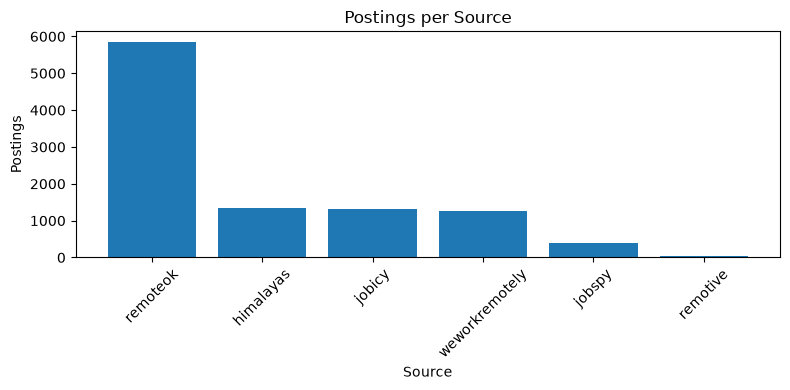

In [25]:
plt.figure(figsize=(8, 4))
plt.bar(source_counts.index, source_counts.values)
plt.xlabel("Source")
plt.ylabel("Postings")
plt.title("Postings per Source")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Eligible Counts

In [26]:
eligible_counts = df["eligible"].value_counts()
eligible_counts

eligible
0    9922
1     283
Name: count, dtype: int64

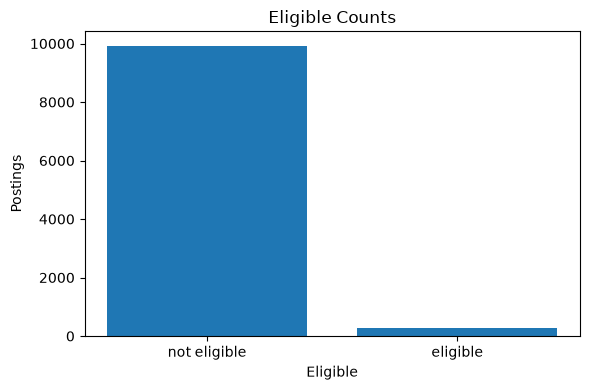

In [27]:
plt.figure(figsize=(6, 4))
plt.bar(["not eligible", "eligible"], eligible_counts.sort_index().values)
plt.xlabel("Eligible")
plt.ylabel("Postings")
plt.title("Eligible Counts")
plt.tight_layout()
plt.show()

## New Postings by Week

In [28]:
week_counts = df["first_seen_at"].dt.tz_convert(None).dt.to_period("W").dt.start_time.value_counts().sort_index()
week_counts

first_seen_at
2026-08-10     241
2026-08-17    1263
2026-08-24     680
2026-08-31    1288
2026-09-07     752
2026-09-14     678
2026-09-21     340
2026-09-28     675
2026-10-05     850
2026-10-12    1122
2026-10-19    1174
2026-10-26     821
2026-11-02     321
Name: count, dtype: int64

In [29]:
print("Busiest week :", week_counts.idxmax().strftime("%Y-%m-%d"), int(week_counts.max()))

Busiest week : 2026-08-31 1288


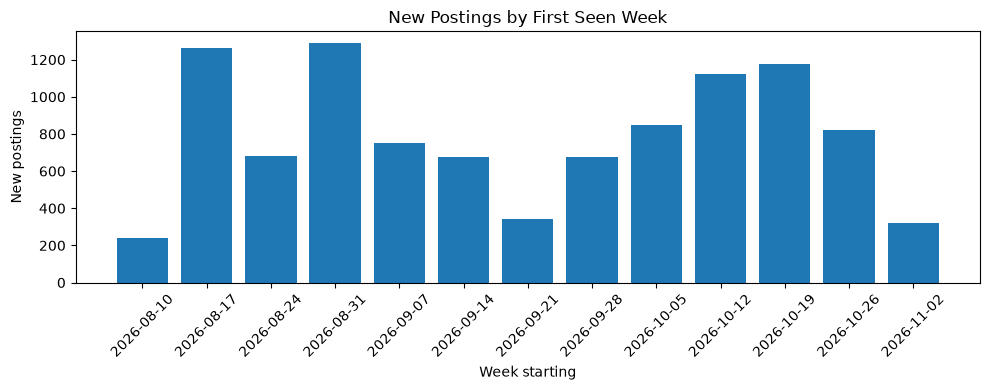

In [30]:
plt.figure(figsize=(10, 4))
plt.bar(week_counts.index.strftime("%Y-%m-%d"), week_counts.values)
plt.xlabel("Week starting")
plt.ylabel("New postings")
plt.title("New Postings by First Seen Week")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Common Words in Eligible Titles

In [31]:
title_words = df.loc[df["eligible"] == 1, "title"].str.lower()

In [32]:
title_words = title_words.str.replace("[^a-z0-9 ]", " ", regex=True)

In [33]:
title_words = title_words.str.split()

In [34]:
title_words = title_words.explode()

In [35]:
word_counts = title_words.value_counts()
word_counts.head(10)

title
engineer     259
data         168
ai           116
senior        52
machine       41
learning      41
junior        34
scientist     30
platform      28
remote        19
Name: count, dtype: int64

In [36]:
print("Top word :", word_counts.index[0], int(word_counts.iloc[0]))

Top word : engineer 259


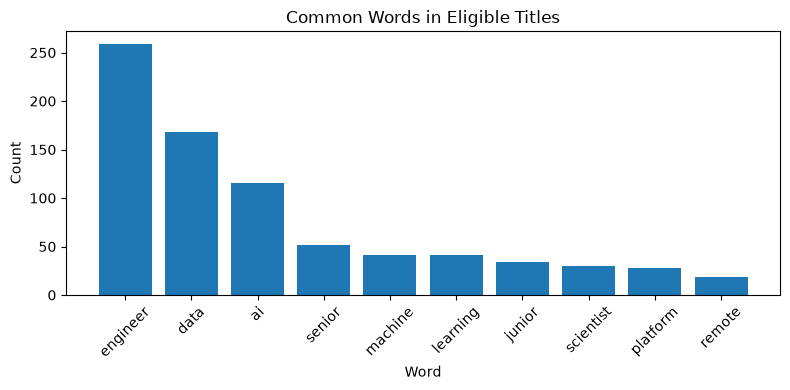

In [37]:
plt.figure(figsize=(8, 4))
plt.bar(word_counts.head(10).index, word_counts.head(10).values)
plt.xlabel("Word")
plt.ylabel("Count")
plt.title("Common Words in Eligible Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Most Common Tags

In [38]:
tag_counts = df["tags"].explode().value_counts()
tag_counts.head(10)

tags
exec                3721
customer support    2980
digital nomad       2693
marketing           2609
ops                 2427
education           2147
dev                 2053
engineer            2051
medical             2030
design              1750
Name: count, dtype: int64

In [39]:
print("Top tag :", tag_counts.index[0], int(tag_counts.iloc[0]))

Top tag : exec 3721


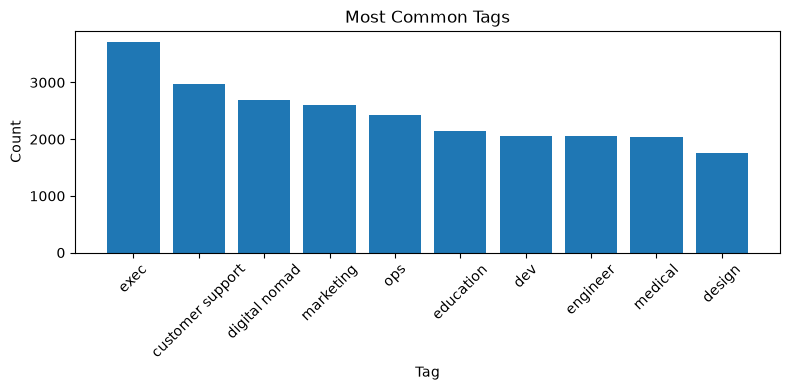

In [40]:
plt.figure(figsize=(8, 4))
plt.bar(tag_counts.head(10).index, tag_counts.head(10).values)
plt.xlabel("Tag")
plt.ylabel("Count")
plt.title("Most Common Tags")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Salary Coverage

In [41]:
salary_counts = df[["salary_min", "salary_max"]].count()

In [42]:
print("Rows with salary_min :", salary_counts["salary_min"])

Rows with salary_min : 1070


In [43]:
print("Rows with salary_max :", salary_counts["salary_max"])

Rows with salary_max : 1051


In [44]:
salary_rows = df.dropna(subset=["salary_min", "salary_max"], how="all").copy()

In [45]:
print("Rows with either salary bound :", len(salary_rows))

Rows with either salary bound : 1073


In [46]:
salary_ranges = df.dropna(subset=["salary_min", "salary_max"]).copy()

In [47]:
print("Rows with both salary bounds :", len(salary_ranges))

Rows with both salary bounds : 1048


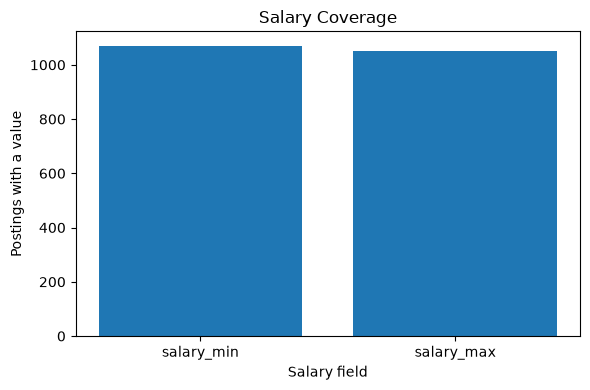

In [48]:
plt.figure(figsize=(6, 4))
plt.bar(salary_counts.index, salary_counts.values)
plt.xlabel("Salary field")
plt.ylabel("Postings with a value")
plt.title("Salary Coverage")
plt.tight_layout()
plt.show()

## Salary Ranges by Currency and Period

In [49]:
salary_rows[["salary_min", "salary_max", "salary_currency", "salary_period"]].head(10)

,salary_min,salary_max,salary_currency,salary_period
124,1700.0,2400.0,EUR,monthly
125,20.0,22.0,USD,hourly
128,65.0,120.0,USD,hourly
129,120000.0,175000.0,USD,annual
131,15.0,80.0,USD,hourly
134,45.0,60.0,USD,hourly
138,4.0,5500.0,USD,monthly
141,110000.0,185000.0,EUR,annual
142,130900.0,220000.0,USD,annual
144,104300.0,136800.0,CAD,annual


In [50]:
salary_summary = salary_rows.groupby(["salary_currency", "salary_period"], dropna=False)[["salary_min", "salary_max"]].agg(["count", "min", "median", "max"]).round(2)

In [51]:
salary_summary

salary_min                                    \
                                   count        min      median        max   
salary_currency salary_period                                                
AUD             annual                 9    60000.0   110000.00   144000.0   
                hourly                 6       26.0       34.83      240.0   
BRL             annual                 1   249000.0   249000.00   249000.0   
                hourly                 1       50.0       50.00       50.0   
CAD             annual                42    55000.0   143000.00   401000.0   
                hourly                 1       23.0       23.00       23.0   
                NaN                    4    85000.0   132000.00   170500.0   
CNY             annual                 2   600000.0   600000.00   600000.0   
CZK             annual                 4  1130000.0  1298000.00  1520000.0   
EUR             annual                52    26000.0    85500.00   154000.0   
                hourly                 3       14.0       14.00       47.0   
                monthly               11     1700.0     3900.00     5500.0   
GBP             annual                27    40000.0   110000.00   170000.0   
INR             annual                 7   600000.0   900000.00  1800000.0   
MXN             annual                 2   450900.0   465450.00   480000.0   
PHP             monthly                6    25000.0    50000.00   100000.0   
PLN             annual                10   248000.0   272000.00   638350.0   
                hourly                 3      110.0      120.00      200.0   
                monthly                7    10080.0    18000.00    32000.0   
SEK             annual                 3   609985.0   878000.00   996819.0   
USD             annual               548     1000.0   150000.00   500000.0   
                hourly               253        4.0       45.00      245.0   
                monthly               52        4.0     1475.00     5300.0   
                weekly                 1     1060.0     1060.00     1060.0   
                NaN                    5       21.0   180000.00   200000.0   
NaN             annual                 4   180000.0   180610.00   215000.0   
                hourly                 6        4.0        8.00       16.0   

                              salary_max                                    
                                   count        min      median        max  
salary_currency salary_period                                               
AUD             annual                 9    66500.0   130000.00   250000.0  
                hourly                 6       26.0       34.83      360.0  
BRL             annual                 1   409000.0   409000.00   409000.0  
                hourly                 1       80.0       80.00       80.0  
CAD             annual                42    65000.0   172900.00   300100.0  
                hourly                 1       23.0       23.00       23.0  
                NaN                    4   115000.0   163000.00   192500.0  
CNY             annual                 2  1000000.0  1000000.00  1000000.0  
CZK             annual                 4  1410000.0  1610000.00  1900000.0  
EUR             annual                51    39000.0   104000.00   226000.0  
                hourly                 3       16.0       16.00       53.0  
                monthly               11     2000.0     5000.00     7559.0  
GBP             annual                27    45000.0   141539.00   225000.0  
INR             annual                 7  1000000.0  1800000.00  2500000.0  
MXN             annual                 2   480000.0   535850.00   591700.0  
PHP             monthly                6    35000.0    65000.00   130000.0  
PLN             annual                10   354000.0   372000.00   751000.0  
                hourly                 3      160.0      180.00      250.0  
                monthly                7    17000.0    23520.00    40000

## USD Annual Salary Ranges

In [52]:
usd_annual = salary_ranges.loc[(salary_ranges["salary_currency"] == "USD") & (salary_ranges["salary_period"] == "annual")]

In [53]:
print("USD annual rows with both salary bounds :", len(usd_annual))

USD annual rows with both salary bounds : 534


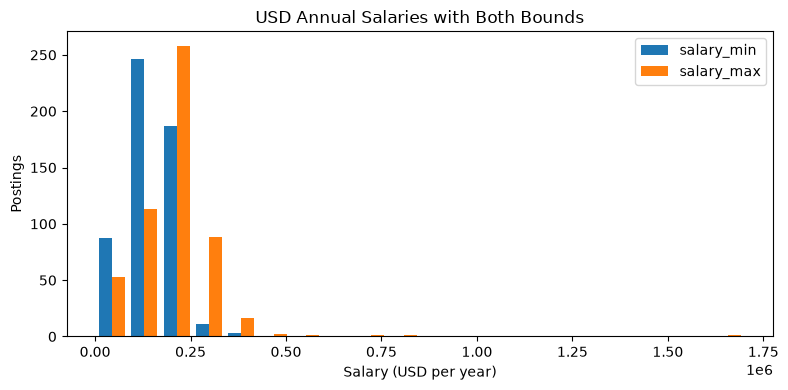

In [54]:
plt.figure(figsize=(8, 4))
plt.hist([usd_annual["salary_min"], usd_annual["salary_max"]], bins=20, label=["salary_min", "salary_max"])
plt.xlabel("Salary (USD per year)")
plt.ylabel("Postings")
plt.title("USD Annual Salaries with Both Bounds")
plt.legend()
plt.tight_layout()
plt.show()

## Days Between First and Last Seen

In [55]:
df["days_observed"] = (df["last_seen_at"] - df["first_seen_at"]).dt.total_seconds() / 86400

In [56]:
df[["first_seen_at", "last_seen_at", "days_observed"]].head()

,first_seen_at,last_seen_at,days_observed
0,2026-08-15 10:16:59.800835+00:00,2026-08-15 10:16:59.800835+00:00,0.0
1,2026-08-15 10:16:59.800835+00:00,2026-08-15 10:16:59.800835+00:00,0.0
2,2026-08-15 10:16:59.800835+00:00,2026-08-15 10:16:59.800835+00:00,0.0
3,2026-08-15 10:16:59.800835+00:00,2026-08-15 10:16:59.800835+00:00,0.0
4,2026-08-15 10:16:59.800835+00:00,2026-08-15 10:16:59.800835+00:00,0.0


In [57]:
print("Rows with missing observation days :", df["days_observed"].isna().sum())

Rows with missing observation days : 0


In [58]:
print("Rows with negative observation days :", (df["days_observed"] < 0).sum())

Rows with negative observation days : 0


In [59]:
observed_days = df.loc[df["days_observed"] >= 0, "days_observed"]

In [60]:
observed_days.describe()

count    10205.000000
mean         3.428510
std         10.239771
min          0.000000
25%          0.000000
50%          0.000000
75%          1.129711
max         80.607779
Name: days_observed, dtype: float64

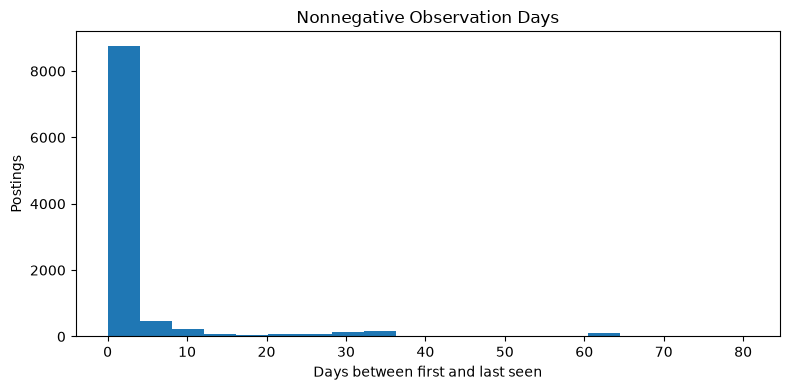

In [61]:
plt.figure(figsize=(8, 4))
plt.hist(observed_days, bins=20)
plt.xlabel("Days between first and last seen")
plt.ylabel("Postings")
plt.title("Nonnegative Observation Days")
plt.tight_layout()
plt.show()

## Wrap-Up

remoteok has the most postings (5846 of 10205) and only 283 are eligible. The week this collection first found the most new postings was 2026-08-31 (1288). The most common word in eligible titles is engineer (259) and the most common tag is exec (3721).

There are 1070 rows with salary_min, 1051 with salary_max, 1048 with both, and 1073 with at least one. Salary summaries keep currency and pay period visible, and the salary chart uses only USD annual rows with both bounds (534). Observation spans average 3.43 days, with a median of 0 and a maximum of 80.61 days. Missing and negative spans are excluded from the summary and chart. These spans measure the gap between first and last sightings, not how long a job stayed open.